# Stable Diffusion with Diffusers

Generate an image by running the text encoder, U-Net, scheduler, and VAE separately. The final function is an img2img exercise.


In [1]:
import matplotlib.pyplot as plt
from PIL import Image
import torch
from tqdm.auto import tqdm
from diffusers import AutoencoderKL, LMSDiscreteScheduler, UNet2DConditionModel
from transformers import CLIPTextModel, CLIPTokenizer


/Users/xyz/opt/miniconda3/envs/image-edit/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Load the components


In [2]:
model_id = "stable-diffusion-v1-5/stable-diffusion-v1-5"
if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"

tokenizer = CLIPTokenizer.from_pretrained(model_id, subfolder="tokenizer")
text_encoder = CLIPTextModel.from_pretrained(model_id, subfolder="text_encoder").to(device).eval()
unet = UNet2DConditionModel.from_pretrained(model_id, subfolder="unet").to(device).eval()
vae = AutoencoderKL.from_pretrained(model_id, subfolder="vae").to(device).eval()
scheduler = LMSDiscreteScheduler(
    beta_start=0.00085,
    beta_end=0.012,
    beta_schedule="scaled_linear",
    num_train_timesteps=1000,
)


Loading weights: 100%|██████████| 196/196 [00:00<00:00, 3358.46it/s]
/Users/xyz/opt/miniconda3/envs/image-edit/lib/python3.14/site-packages/huggingface_hub/utils/_validators.py:205: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


## Encode the prompts

The empty prompts provide the unconditional predictions used for classifier free guidance.


In [3]:
prompts = [
    "Photograph of an astronaut riding a horse",
    "Sketch of an apple on a table",
    "Red sports car drifting through Tokyo at night",
]
batch_size = len(prompts)
num_inference_steps = 100
guidance_scale = 7.5
height = width = 512

text_inputs = tokenizer(
    prompts,
    padding="max_length",
    max_length=tokenizer.model_max_length,
    truncation=True,
    return_tensors="pt",
)
with torch.inference_mode():
    text_embeddings = text_encoder(text_inputs.input_ids.to(device))[0]


In [4]:
uncond_inputs = tokenizer(
    [""] * batch_size,
    padding="max_length",
    max_length=text_inputs.input_ids.shape[-1],
    return_tensors="pt",
)
with torch.inference_mode():
    uncond_embeddings = text_encoder(uncond_inputs.input_ids.to(device))[0]


In [5]:
embeddings = torch.cat([uncond_embeddings, text_embeddings])


## Denoise in latent space


The scheduler starts with noisy latents and reduces the noise over successive steps.


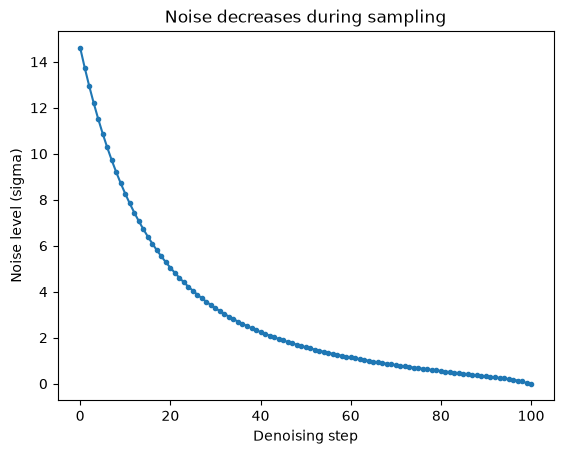

In [6]:
scheduler.set_timesteps(num_inference_steps)
plt.plot(scheduler.sigmas.cpu(), marker=".")
plt.xlabel("Denoising step")
plt.ylabel("Noise level (sigma)")
plt.title("Noise decreases during sampling")
plt.show()


In [7]:
latents = torch.randn(
    (batch_size, unet.config.in_channels, height // 8, width // 8),
    device=device,
)
latents *= scheduler.init_noise_sigma

with torch.inference_mode():
    for t in tqdm(scheduler.timesteps):
        model_input = torch.cat([latents, latents])
        model_input = scheduler.scale_model_input(model_input, t)
        noise_pred = unet(model_input, t, encoder_hidden_states=embeddings).sample
        noise_uncond, noise_text = noise_pred.chunk(2)
        guided_noise = noise_uncond + guidance_scale * (noise_text - noise_uncond)
        latents = scheduler.step(guided_noise, t, latents).prev_sample


100%|██████████| 100/100 [05:09<00:00,  3.09s/it]


## Decode and compare the images


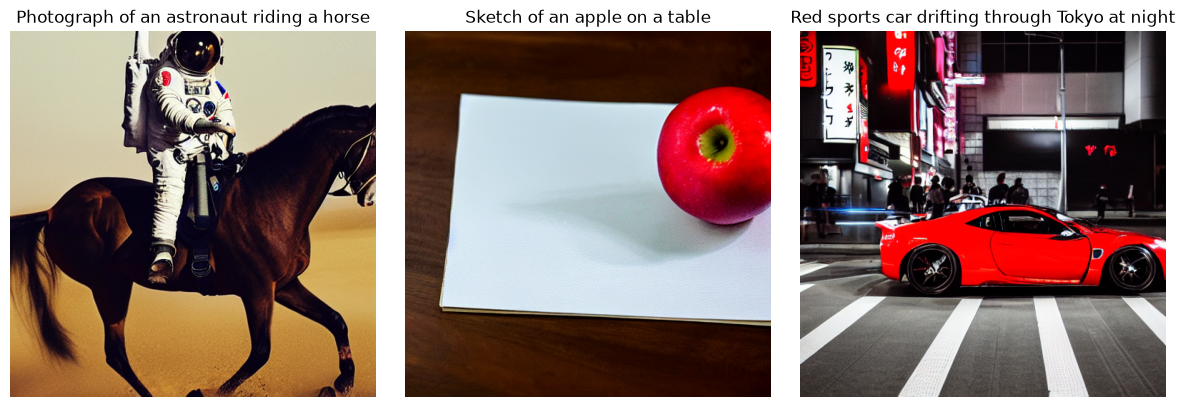

In [8]:
with torch.inference_mode():
    images = vae.decode(latents / vae.config.scaling_factor).sample
images = (images / 2 + 0.5).clamp(0, 1)
images = (images * 255).byte().permute(0, 2, 3, 1).cpu().numpy()

fig, axes = plt.subplots(1, batch_size, figsize=(4 * batch_size, 4), squeeze=False)
for ax, image, prompt in zip(axes[0], images, prompts):
    ax.imshow(Image.fromarray(image))
    ax.set_title(prompt, wrap=True)
    ax.axis("off")
plt.tight_layout()
plt.show()


## Exercise: image to image

Implement the function using the components above. Encode the input image with the VAE, add noise according to `strength`, denoise with the prompt, then decode the result.


In [9]:
def img2img(image: Image.Image, prompt: str, strength: float = 0.7) -> Image.Image:
    pass
